# Анализ системы метрик приложения

В проекте - приложение, которое предоставляет пользователям доступ к развлекательному контенту: видео, подкастам и блогам. Пользователи могут выбрать несколько пакетов контента. Пакеты различаются по цене, объёму и содержанию.

К началу лета в приложении появился новый вид контента - спортивный. С его помощью менеджеры стремятся расширить аудиторию, добавив в неё пользователей, которые увлекаются спортом и здоровым образом жизни.

К запуску нового контента была скорректирована маркетинговая стратегия привлечения пользователей. Согласно бизнес-модели продукта, привлечение должно окупиться за первые 28 дней (4 недели).

После запуска нового контента и изменения стратегии интерес к продукту в целом вырос, но выручка начала стагнировать. Нужно разобраться, почему это происходит.

### Данные

Есть данные о посещениях приложения, покупках и расходах на маркетинг.
Данные собраны в трёх датасетах.

1. Датасет `ppro_visits.csv` - информация о посещениях приложения пользователями, которые зарегистрировались с 1 апреля 2024 года по 30 ноября 2024 года:
    - `user_id` - уникальный идентификатор пользователя;
    - `region` - страна пользователя;
    - `device` - категория устройства пользователя;
    - `channel` - идентификатор рекламного источника, из которого пришёл пользователь;
    - `session_start` - дата и время начала сессии;
    - `session_end` - дата и время окончания сессии.

2. Датасет `ppro_orders.csv` - информация о покупках:
    - `user_id` - уникальный идентификатор пользователя, который сделал покупку;
    - `event_dt` - дата и время покупки;
    - `revenue` - выручка.

3. Датасет `ppro_costs.csv` - информация о затратах на маркетинг:
    - `dt` - дата
    - `channel` - идентификатор рекламного источника;
    - `costs` - затраты на этот рекламный источник в этот день.

### План проекта

- Загрузить и предобработать данные.
- Подготовить данные для когортного анализа.
- Рассчитать и проанализировать метрики вовлечённости в продукт.
- Рассчитать и проанализировать финансовые метрики CAC, LTV и ROI за первые 28 дней с момента привлечения.
- Исследовать метрики в разрезе источника привлечения.
- Рассчитать период окупаемости маркетинговых вложений.
- Сформулировать выводы и рекомендации.

## Загрузка и предобработка данных

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>1. Импортируем необходимые для работы библиотеки:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>2. Загружаем три датасета: ppro_visits.csv, ppro_orders.csv, ppro_costs.csv:

In [2]:
visits = pd.read_csv('***', parse_dates=['session_start','session_end'])
orders = pd.read_csv('***', parse_dates=['event_dt'])
costs = pd.read_csv('***', parse_dates=['dt'])

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>3. Посмотрим информацию о датасетах:

In [3]:
print('Информация о датасете visits \n')
visits.info()
print('\nПропуски в visits:\n', visits.isna().sum())
print('\n \nИнформация о датасете orders \n')
orders.info()
print('\nПропуски в orders:\n', orders.isna().sum())
print('\n \nИнформация о датасете costs \n')
costs.info()
print('\nПропуски в costs:\n', costs.isna().sum())

Информация о датасете visits 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161865 entries, 0 to 161864
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   user_id        161865 non-null  int64         
 1   region         161865 non-null  object        
 2   device         161865 non-null  object        
 3   channel        161865 non-null  object        
 4   session_start  161865 non-null  datetime64[ns]
 5   session_end    161865 non-null  datetime64[ns]
dtypes: datetime64[ns](2), int64(1), object(3)
memory usage: 7.4+ MB

Пропуски в visits:
 user_id          0
region           0
device           0
channel          0
session_start    0
session_end      0
dtype: int64

 
Информация о датасете orders 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33893 entries, 0 to 33892
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----  

Все столбцы имеют нужный нам формат. Даты из формата `object` мы перевели в `datetime64[ns]` еще на этапе загрузки датасета для дальнейшей работы с ними. Так же видим, что в данных нет столбцов с пропусками, можно проверить на дубликаты, для полной уверенности в чистоте данных.

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>4. Проверим диапазон дат в датасете:

In [4]:
print('Диапазон дат в датасете visits:', visits['session_start'].min(), '-', visits['session_start'].max())

Диапазон дат в датасете visits: 2024-04-01 00:07:00 - 2024-11-30 23:59:00


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>5. Проверим данные на дубликаты:

In [5]:
data = ['visits', 'orders', 'costs']
before = [len(visits), len(orders), len(costs)]

visits = visits.drop_duplicates().reset_index(drop=True)
orders = orders.drop_duplicates().reset_index(drop=True)
costs = costs.drop_duplicates().reset_index(drop=True)

after = [len(visits), len(orders), len(costs)]
removed = [b - a for b, a in zip(before, after)]

result = pd.DataFrame({
    'Датасет': data,
    'До очистки': before,
    'После очистки': after,
    'Удалено строк': removed})

display(result)

,Датасет,До очистки,После очистки,Удалено строк
0,visits,161865,161865,0
1,orders,33893,33893,0
2,costs,976,976,0


В результате проверки дубликатов в датасетах не обнаружено.

**Вывод:**

Данные загружены. Все даты переведены в `datetime`, пропусков и дубликатов нет - данные чистые. Диапазон дат в визитах с 1 апреля по 30 ноября 2024 года, покрывает весь нужный период. Форматы столбцов соответствуют задачам. Можно переходить к подготовке когорт.

## Подготовка данных к когортному анализу

Подготовим данные к когортному анализу с учётом того, что мы будем изучать окупаемость привлечения пользователей **за первые 28 дней**.

Для каждого пользователя найдём:
- дату первой сессии (дата привлечения пользователя, `first_dt`);
- канал привлечения (`first_channel`);
- стоимость привлечения пользователя (`cac`).

Результаты сохраним в новой таблице `profiles`.

Добавим к данным с событиями и покупками информацию о первом источнике привлечения и дату привлечения пользователя из созданной таблицы. После этого рассчитаем дневной лайфтайм для каждого события или покупки и добавим в таблицу в виде целого числа. 

В дальнейшем при проведении когортного анализа используем информацию о первом источнике привлечения пользователя.

---

Сформируем таблицу профилей. Затем добавим в таблицы визитов и покупок когортные признаки и рассчитаем lifetime.
Также здесь мы зададим палитру цветов для каналов, чтобы на всех графиках в проекте каждый канал имел один и тот же цвет.

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>1. Создадим таблицу профилей с датой первого привлечения и источником:

In [6]:
profiles = visits.sort_values(by='session_start').groupby('user_id').agg(
            first_dt = ('session_start', 'min'),
            first_channel = ('channel','first')).reset_index()
profiles['first_dt'] = profiles['first_dt'].dt.normalize()

display(profiles.head())

,user_id,first_dt,first_channel
0,26034876,2024-05-29,FaceBoom
1,69890364,2024-06-28,RocketSuperAds
2,75610104,2024-06-09,FaceBoom
3,76692397,2024-10-21,FaceBoom
4,80224421,2024-06-21,FaceBoom


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>2. Добавим разделение на месяц и неделю привлечения пользователей, это понадобится нам в дальнейшем:

In [7]:
profiles['dt'] = profiles['first_dt']
profiles['acq_month'] = profiles['first_dt'].astype('datetime64[M]')
profiles['acq_week'] = profiles['first_dt'].dt.to_period('W-MON').dt.start_time

display(profiles.head())

,user_id,first_dt,first_channel,dt,acq_month,acq_week
0,26034876,2024-05-29,FaceBoom,2024-05-29,2024-05-01,2024-05-28
1,69890364,2024-06-28,RocketSuperAds,2024-06-28,2024-06-01,2024-06-25
2,75610104,2024-06-09,FaceBoom,2024-06-09,2024-06-01,2024-06-04
3,76692397,2024-10-21,FaceBoom,2024-10-21,2024-10-01,2024-10-15
4,80224421,2024-06-21,FaceBoom,2024-06-21,2024-06-01,2024-06-18


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>3. Посчитаем количество новых пользователей в разрезе дат и каналов:

In [8]:
daily_users = (
    profiles
    .groupby(['dt', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name='users_count'))
daily_users.head()

,dt,first_channel,users_count
0,2024-04-01,FaceBoom,133
1,2024-04-01,MediaTornado,80
2,2024-04-01,RocketSuperAds,70
3,2024-04-01,TipTop,73
4,2024-04-02,FaceBoom,94


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>4. Рассчитаем CAC в разрезе дат и каналов:

In [9]:
cac = (costs
       .groupby(['channel','dt'])['costs'].sum().reset_index()
       .merge(profiles.groupby(['first_channel','first_dt'])['user_id'].nunique(),
              left_on=['dt','channel'],
              right_on=['first_dt','first_channel'], how='inner')
       .assign(cac = lambda x: x['costs']/x['user_id']))
cac.columns = ['first_channel', 'first_dt', 'costs', 'user_id', 'cac']


cac.head()

,first_channel,first_dt,costs,user_id,cac
0,FaceBoom,2024-04-01,124.938874,133,0.939390
1,FaceBoom,2024-04-02,88.147779,94,0.937742
2,FaceBoom,2024-04-03,120.779457,133,0.908116
3,FaceBoom,2024-04-04,98.981253,105,0.942679
4,FaceBoom,2024-04-05,109.044760,110,0.991316


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>5. Добавим CAC в профили:

In [10]:
profiles = profiles.merge(cac[['first_dt','first_channel','cac']], on=['first_dt','first_channel'], how='left')

profiles.head()

,user_id,first_dt,first_channel,dt,acq_month,acq_week,cac
0,26034876,2024-05-29,FaceBoom,2024-05-29,2024-05-01,2024-05-28,0.953250
1,69890364,2024-06-28,RocketSuperAds,2024-06-28,2024-06-01,2024-06-25,0.604917
2,75610104,2024-06-09,FaceBoom,2024-06-09,2024-06-01,2024-06-04,1.196159
3,76692397,2024-10-21,FaceBoom,2024-10-21,2024-10-01,2024-10-15,1.147967
4,80224421,2024-06-21,FaceBoom,2024-06-21,2024-06-01,2024-06-18,1.208981


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>6. Добавляем данные профилей в визиты и покупки:

In [11]:
cols_to_merge = ['user_id', 'first_dt', 'first_channel', 'acq_month', 'acq_week', 'cac']
visits = visits.merge(profiles[cols_to_merge], on='user_id', how='left')
orders = orders.merge(profiles[cols_to_merge], on='user_id', how='left')

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>7. Рассчитаем лайфтайм в днях:

In [12]:
visits['lifetime'] = (visits['session_start'] - visits['first_dt']).dt.days.astype('int')
orders['lifetime'] = (orders['event_dt'] - orders['first_dt']).dt.days.astype('int')

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>8. Задаем единую цветовую палитру на будущее для всех каналов, чтобы графики легко читались

In [13]:
unique_channels = profiles['first_channel'].unique()
palette = sns.color_palette("Set1", len(unique_channels))
channel_colors = dict(zip(unique_channels, palette))

**Вывод:**

Сформировали таблицу профилей. Для каждого пользователя определили дату первой сессии, канал привлечения и CAC. Добавили месячную и недельную разбивку по дате привлечения.
Перенесли эти признаки в таблицы визитов и заказов, рассчитали `lifetime` как целое число дней от первой сессии до события.
Задали единую цветовую палитру для каналов - теперь все графики будут визуально согласованы. Данные полностью готовы для когортного анализа.

## Анализ месячной динамики основных метрик продукта

<div style="background-color:#8890FC; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
Начнём анализ данных с изучения динамики активности пользователей и их вовлечённости в продукт. Рассчитаем по всем данным значения DAU, MAU и Stickiness и визуализируем их. Активными будет считать всех пользователей, которые взаимодействовали с приложением.</div>

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>1. Добавим столбцы с датой и месяцем сессии:

In [14]:
visits['session_date'] = visits['session_start'].dt.normalize()
visits['session_month'] = visits['session_start'].astype('datetime64[M]')

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>2. Расчёт DAU, MAU и Stickiness:

In [15]:
#DAU по дням
dau_daily = visits.groupby('session_date')['user_id'].nunique().reset_index()
dau_daily['session_month'] = dau_daily['session_date'].astype('datetime64[M]')

#Средний DAU по месяцам
dau_month = dau_daily.groupby('session_month')['user_id'].mean().reset_index()
dau_month = dau_month.rename(columns={'user_id': 'dau_avg'})

#MAU по месяцам
mau = visits.groupby('session_month')['user_id'].nunique().reset_index()
mau = mau.rename(columns={'user_id': 'mau'})

#Stickiness
monthly_activity = dau_month.merge(mau, on='session_month', how='left')
monthly_activity['stickiness'] = (monthly_activity['dau_avg'] / monthly_activity['mau']) * 100
monthly_activity

,session_month,dau_avg,mau,stickiness
0,2024-04-01,488.333333,9069,5.384644
1,2024-05-01,576.967742,10849,5.318165
2,2024-06-01,580.366667,10240,5.667643
3,2024-07-01,615.000000,10864,5.660898
4,2024-08-01,681.193548,11977,5.687514
5,2024-09-01,724.100000,12089,5.989743
6,2024-10-01,773.193548,13036,5.931218
7,2024-11-01,868.133333,14097,6.158284


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>4. Визуализация MAU и DAU по месяцам

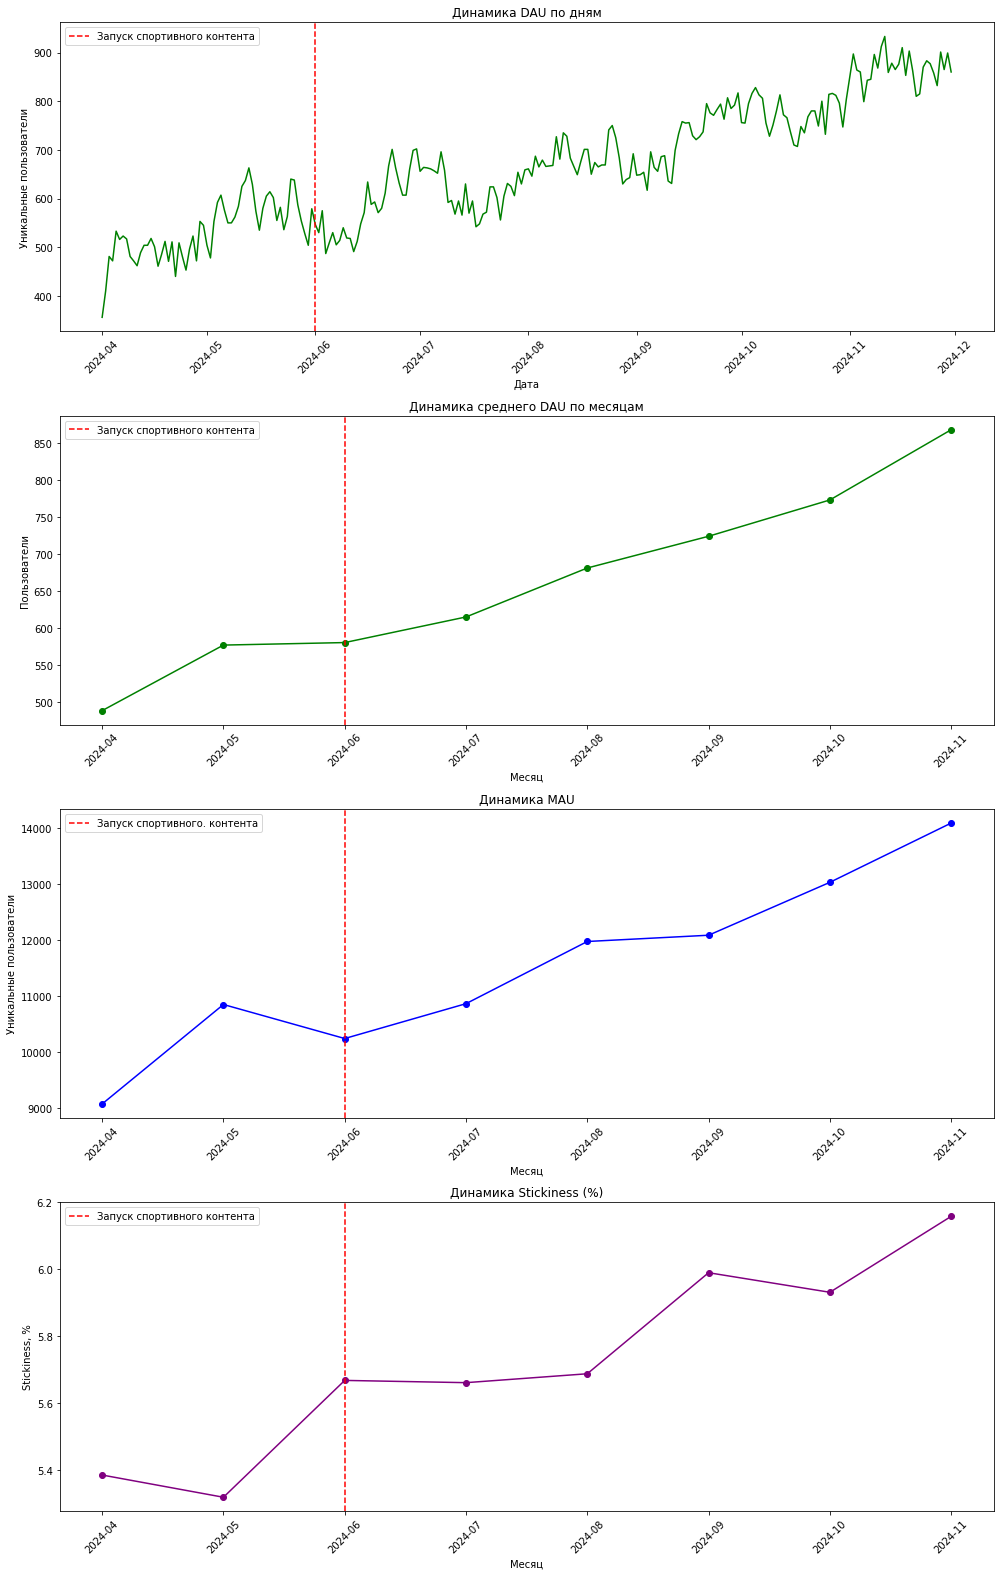

In [16]:
launch_date = pd.Timestamp('2024-06-01')

fig, axes = plt.subplots(4, 1, figsize=(14, 22))

#DAU по дням
axes[0].plot(
    dau_daily['session_date'],
    dau_daily['user_id'],
    color='green')
axes[0].axvline(
    x=launch_date,
    color='red',
    linestyle='--',
    label='Запуск спортивного контента')
axes[0].set_title('Динамика DAU по дням')
axes[0].set_xlabel('Дата')
axes[0].set_ylabel('Уникальные пользователи')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

#Средний DAU по месяцам
axes[1].plot(
    monthly_activity['session_month'].dt.strftime('%Y-%m'),
    monthly_activity['dau_avg'],
    marker='o',
    color='green')
axes[1].axvline(x='2024-06', color='red', linestyle='--', label='Запуск спортивного контента')
axes[1].set_title('Динамика среднего DAU по месяцам')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Пользователи')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

#MAU по месяцам
axes[2].plot(
    monthly_activity['session_month'].dt.strftime('%Y-%m'),
    monthly_activity['mau'],
    marker='o',
    color='blue')
axes[2].axvline(x='2024-06', color='red', linestyle='--', label='Запуск спортивного. контента')
axes[2].set_title('Динамика MAU')
axes[2].set_xlabel('Месяц')
axes[2].set_ylabel('Уникальные пользователи')
axes[2].tick_params(axis='x', rotation=45)
axes[2].legend()

#Stickiness по месяцам
axes[3].plot(
    monthly_activity['session_month'].dt.strftime('%Y-%m'),
    monthly_activity['stickiness'],
    marker='o',
    color='purple')
axes[3].axvline(x='2024-06', color='red', linestyle='--', label='Запуск спортивного контента')
axes[3].set_title('Динамика Stickiness (%)')
axes[3].set_xlabel('Месяц')
axes[3].set_ylabel('Stickiness, %')
axes[3].tick_params(axis='x', rotation=45)
axes[3].legend()

plt.tight_layout()
plt.show()

**Вывод:**

- В июне 2024 года наблюдается устойчивый рост **DAU** и **MAU** с июля по ноябрь. При этом в июне произошёл краткосрочный спад **MAU** по сравнению с маем, но уже с июля показатель пошёл вверх и к ноябрю достиг 14 000. Средний **DAU** также стабильно растёт с июня до ноября.

- **Stickiness** после запуска выросла с 5,3% в мае до 5,7% в июне и продолжает увеличиваться, достигнув 6,2% в ноябре. Это говорит о том, что пользователи стали чаще возвращаться в приложение.

- В целом активность и вовлечённость растут, поэтому стагнация выручки не связана с падением трафика. Причины нужно искать в монетизации или качестве привлечённой аудитории.

<div style="background-color:#8890FC; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
В разрезе каждого месяца привлечения новых пользователей рассчитаем:
    
- Среднюю стоимость привлечения пользователя (CAC).
- Значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения.

При расчёте LTV и ROI будем учитывать *всех* привлечённых пользователей когорты.
</div> 

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>1. Посчитаем расходы и количество пользователей по когортам:

In [17]:
monthly_cohorts = profiles.groupby('acq_month').agg(users=('user_id', 'nunique'), total_cac=('cac', 'sum')).reset_index()
monthly_cohorts['avg_cac'] = monthly_cohorts['total_cac'] / monthly_cohorts['users']
display(monthly_cohorts)

,acq_month,users,total_cac,avg_cac
0,2024-04-01,9069,6663.052333,0.734706
1,2024-05-01,9789,7327.775412,0.748572
2,2024-06-01,8719,8492.116887,0.973978
3,2024-07-01,8742,9217.078561,1.054344
4,2024-08-01,9518,10999.013650,1.155601
5,2024-09-01,9198,10838.014747,1.178301
6,2024-10-01,9520,12595.403113,1.323047
7,2024-11-01,10301,13598.849128,1.320148


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>2. Рассчитаем динамику LTV за первые 28 дней Lifetime:

In [18]:
orders_28d = orders[orders['lifetime'] < 28]
monthly_revenue = orders_28d.groupby('acq_month')['revenue'].sum().reset_index()
display(monthly_revenue)

,acq_month,revenue
0,2024-04-01,7425.63
1,2024-05-01,8141.76
2,2024-06-01,7447.84
3,2024-07-01,9991.41
4,2024-08-01,10367.05
5,2024-09-01,10085.88
6,2024-10-01,11449.71
7,2024-11-01,8893.98


<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>3. Считаем  LTV и ROI:

In [19]:
cohort_metrics = monthly_cohorts.merge(monthly_revenue, on='acq_month', how='left').fillna(0)
cohort_metrics['ltv'] = cohort_metrics['revenue'] / cohort_metrics['users']
cohort_metrics['roi'] = ((cohort_metrics['ltv'] - cohort_metrics['avg_cac']) / cohort_metrics['avg_cac']) * 100

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>4. Визуализируем полученные данные:

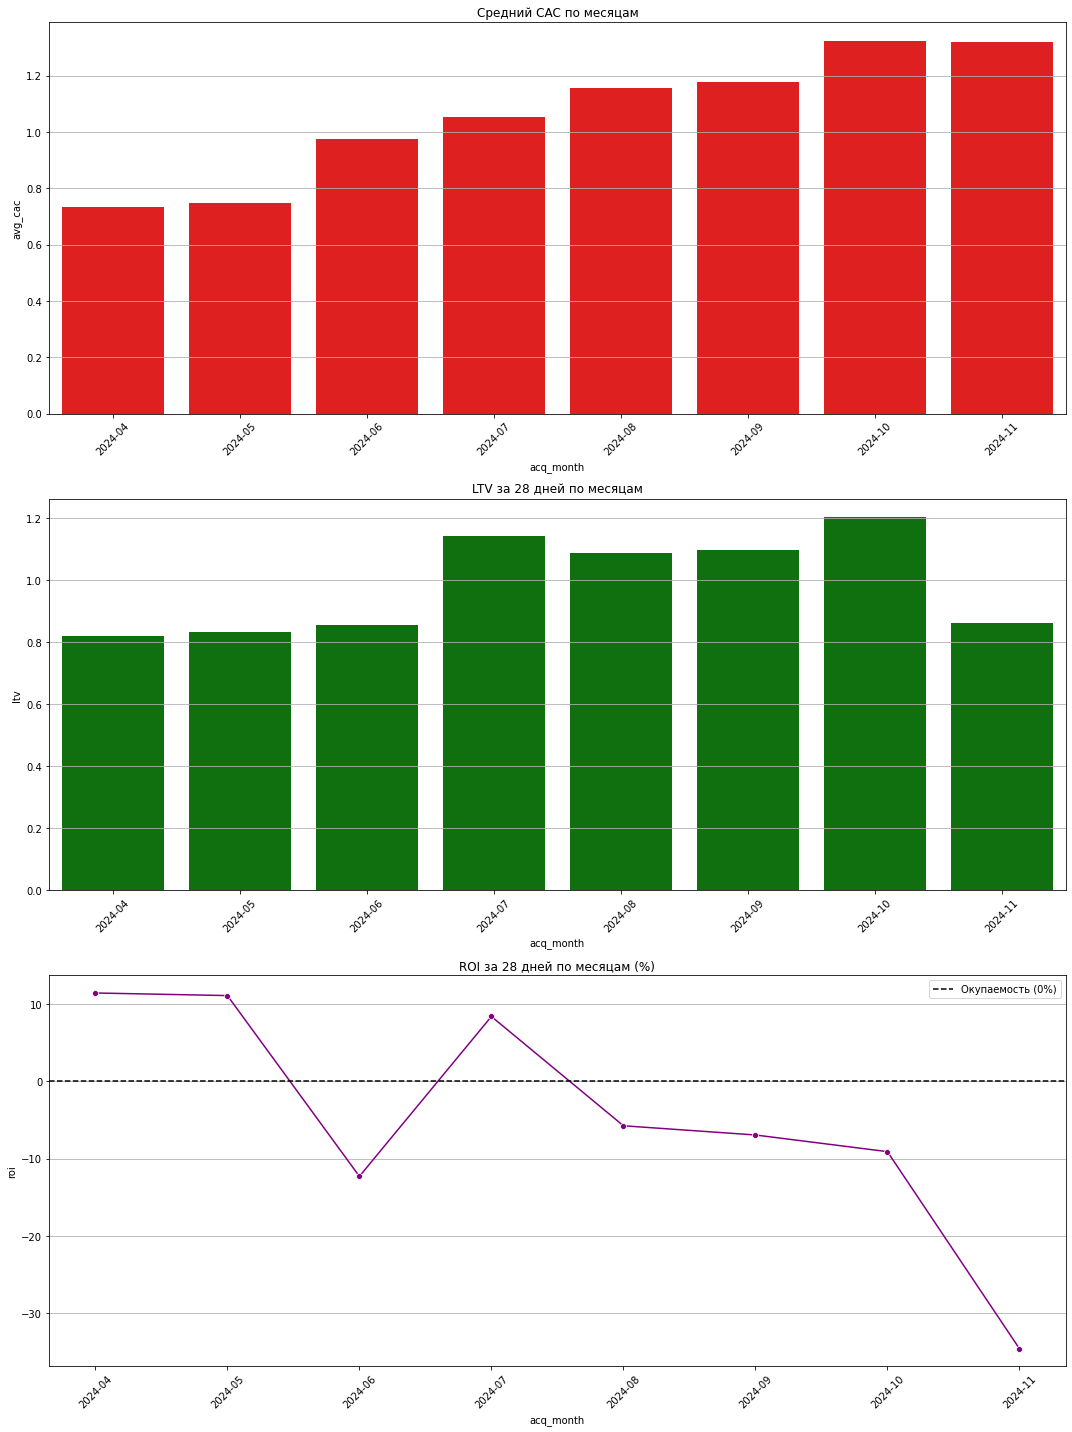

In [20]:
ig, ax = plt.subplots(3, 1, figsize=(15, 20))
months_str = cohort_metrics['acq_month'].dt.strftime('%Y-%m')
for a in ax:
    a.grid(True, axis='y', alpha=1)
#CAC
sns.barplot(x=months_str, y=cohort_metrics['avg_cac'], ax=ax[0], color='red')
ax[0].set_title('Средний CAC по месяцам')
ax[0].tick_params(axis='x', rotation=45)

#LTV
sns.barplot(x=months_str, y=cohort_metrics['ltv'], ax=ax[1], color='green')
ax[1].set_title('LTV за 28 дней по месяцам')
ax[1].tick_params(axis='x', rotation=45)

#ROI
sns.lineplot(x=months_str, y=cohort_metrics['roi'], ax=ax[2], marker='o', color='purple')
ax[2].axhline(0, ls='--', color='black', label='Окупаемость (0%)') 
ax[2].set_title('ROI за 28 дней по месяцам (%)')
ax[2].tick_params(axis='x', rotation=45)
ax[2].legend()

plt.tight_layout()
plt.show()

**Вывод:**

С апреля по ноябрь стоимость привлечения нового пользователя неуклонно растёт. Особенно заметный скачок произошёл после запуска спортивного контента в июне. При этом доход, который пользователь приносит за первые 28 дней, не поспевает за этим ростом. В итоге окупаемость, которая в начале периода была в плюсе, с лета ушла в минус и к ноябрю стала глубоко отрицательной.

То есть мы платим за привлечение всё больше, а пользователи платят нам всё меньше относительно этих затрат. Это главная причина стагнации выручки - она не в трафике, а в экономике привлечения.

## Анализ метрик в разрезе источника привлечения

Теперь необходимо разобраться, какие источники привлечения перспективны, а какие за 28 дней не окупились.

<div style="background-color:#8890FC; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
Определим самые популярные источники привлечения:
    
- Посчитаем общее число привлечённых пользователей для каждого источника.
- Визуализируем динамику набора новых пользователей по дням в каждом источнике.
- Рассчитаем и визуализируем динамику DAU, MAU и Stickiness по источникам привлечения.</div>

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>1. Посмотрим на общее количество привлеченных пользователей по каналам за наблюдаемый период:

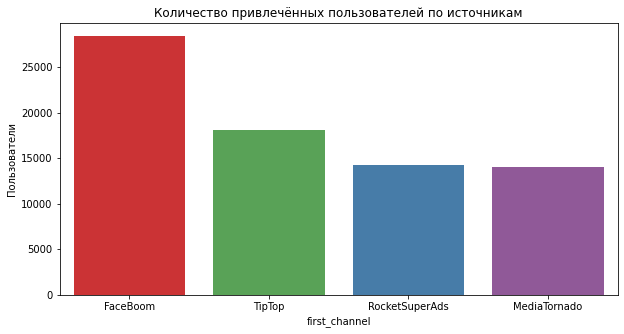

In [21]:
channel_users = profiles.groupby('first_channel').agg({'user_id': 'nunique'}).sort_values('user_id', ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=channel_users, x='first_channel', y='user_id', palette=channel_colors)
plt.title('Количество привлечённых пользователей по источникам')
plt.ylabel('Пользователи')
plt.show()

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>2. Динамика набора новых пользователей по дням в каждом источнике:

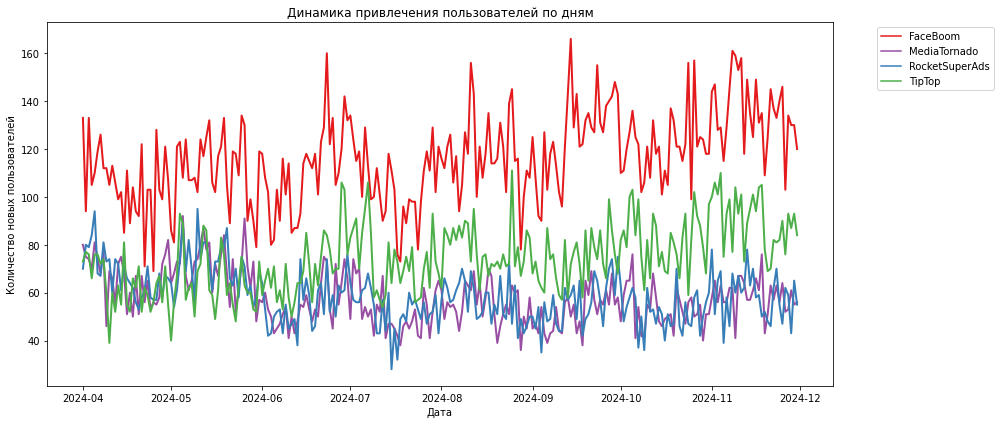

In [22]:
daily_channel = profiles.groupby(['dt', 'first_channel']).agg({'user_id': 'nunique'}).reset_index()
plt.figure(figsize=(14, 6))
sns.lineplot(data=daily_channel, x='dt', y='user_id', hue='first_channel', palette=channel_colors, linewidth=2)
plt.title('Динамика привлечения пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Количество новых пользователей')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Вывод:**
    
Самый популярный канал - FaceBoom. На него приходится основная масса новых пользователей. Остальные источники распределены примерно поровну, с небольшим перевесом у TipTop.
В динамике привлечения по дням картина устойчивая. FaceBoom стабильно даёт наибольший суточный приток, остальные каналы идут на уровне 40–80 пользователей в день с периодическими колебаниями. Резких провалов или всплесков ни у одного источника нет.
Пока что главный источник - FaceBoom, и именно его поведение будет сильнее всего влиять на общие финансовые результаты.

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>3. Рассчитаем и визуализируем динамику DAU, MAU и Stickiness по источникам привлечения:

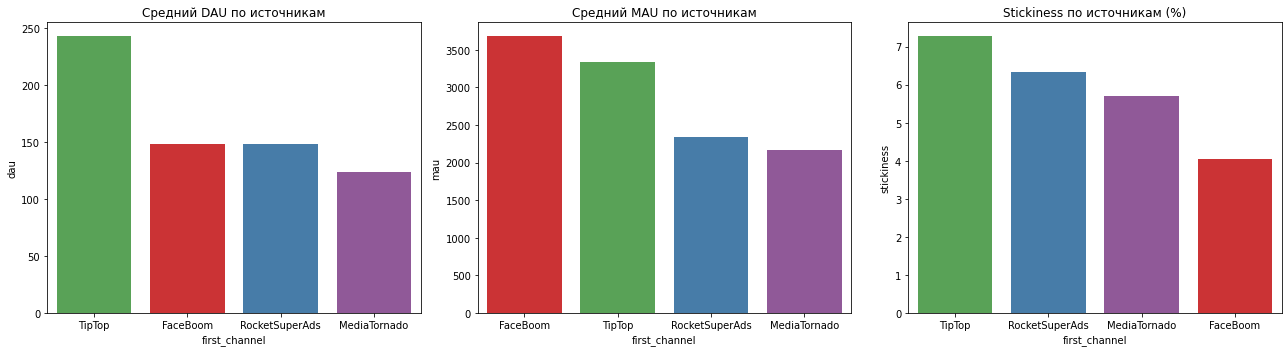

In [23]:
dau_channel = visits.groupby(['session_date', 'first_channel'])['user_id'].nunique().reset_index()
dau_channel_avg = dau_channel.groupby('first_channel')['user_id'].mean().reset_index(name='dau')

mau_channel = visits.groupby(['session_month', 'first_channel'])['user_id'].nunique().reset_index()
mau_channel_avg = mau_channel.groupby('first_channel')['user_id'].mean().reset_index(name='mau')

channel_metrics = dau_channel_avg.merge(mau_channel_avg, on='first_channel')
channel_metrics['stickiness'] = (channel_metrics['dau'] / channel_metrics['mau']) * 100

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=channel_metrics.sort_values('dau', ascending=False), x='first_channel', y='dau', ax=ax[0], palette=channel_colors)
ax[0].set_title('Средний DAU по источникам')

sns.barplot(data=channel_metrics.sort_values('mau', ascending=False), x='first_channel', y='mau', ax=ax[1], palette=channel_colors)
ax[1].set_title('Средний MAU по источникам')

sns.barplot(data=channel_metrics.sort_values('stickiness', ascending=False), x='first_channel', y='stickiness', ax=ax[2], palette=channel_colors)
ax[2].set_title('Stickiness по источникам (%)')
plt.tight_layout()
plt.show()

**Вывод:**

FaceBoom лидирует по общему охвату - у него самая высокая месячная аудитория. Однако по качеству аудитории TipTop вырывается вперёд. Пользователи с канала TipTop возвращаются заметно чаще.
Дальше надо смотреть, какой источник приносит реальные деньги.

Однако анализ вовлеченности показывает важный нюанс: несмотря на меньший объем трафика, каналы MediaTornado и RocketSuperAds демонстрируют хорошие показатели Stickiness. Пользователи из этих небольших каналов задерживаются в приложении и возвращаются чаще, чем пользователи из FaceBoom.

<div style="background-color:#8890FC; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
Изучим динамику изменения метрик на 28-й день в разрезе источника. Проведём анализ с выделением недельных когорт по дате привлечения. Рассчитаем и визуализируем:
    
- Скользящее удержание на 14-й день с момента привлечения (за период с 14-го по 28-й день).
- Конверсию в покупку.
- Недельную динамику затрат на маркетинг по каждому источнику привлечения.
- Динамику среднего CAC, значений LTV и ROI.</div>

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>1. Для начала уберём когорты, которые имеют неполные данные за 28 дней. Так мы не будем искажать анализ:</b> 

In [24]:
max_date = visits['session_start'].max()
horizon_date = max_date - pd.Timedelta(days=28)
profiles_mature = profiles[profiles['first_dt'] <= horizon_date].copy()

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>2. Посчитаем выручку за 28 дней:</b> 

In [25]:
orders_28d = orders[orders['lifetime'] <= 28]
user_rev = orders_28d.groupby('user_id')['revenue'].sum().reset_index()

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>3. Скользящее удержание (с 14 по 28 день):</b> 

In [26]:
active_14_28 = visits[(visits['lifetime'] >= 14) & (visits['lifetime'] <= 28)][['user_id']].drop_duplicates()
active_14_28['retained'] = 1

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>4. Соберём таблицу профилей. К таблице пользователей добавим выручку и признак покупки, присоединим флаг удержания в период 14-28 дней, NA заменяем нулями:</b> 

In [27]:
profiles_rev = profiles_mature.merge(user_rev, on='user_id', how='left')
profiles_rev['revenue'] = profiles_rev['revenue'].fillna(0)
profiles_rev['purchased'] = (profiles_rev['revenue'] > 0).astype(int)

profiles_rev = profiles_rev.merge(active_14_28, on='user_id', how='left')
profiles_rev['retained'] = profiles_rev['retained'].fillna(0)

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>5. Агрегируем недельные метрики по каналам:</b> 

In [28]:
weekly_metrics = profiles_rev.groupby(['acq_week', 'first_channel']).agg(
    users=('user_id', 'count'),
    purchasers=('purchased', 'sum'),
    total_revenue=('revenue', 'sum'),
    retained_users=('retained', 'sum'),
    avg_cac=('cac', 'mean')
).reset_index()

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>6. Рассчитываем итоговые коэффициенты:</b> 

In [29]:
weekly_metrics['cr_28d'] = (weekly_metrics['purchasers'] / weekly_metrics['users']) * 100
weekly_metrics['rr_14_28d'] = (weekly_metrics['retained_users'] / weekly_metrics['users']) * 100
weekly_metrics['ltv'] = weekly_metrics['total_revenue'] / weekly_metrics['users']
weekly_metrics['roi'] = (weekly_metrics['ltv'] / weekly_metrics['avg_cac'] - 1) * 100

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>7. Динамика маркетинговых затрат по неделям:</b> 

In [30]:
costs['week'] = costs['dt'].dt.to_period('W-MON').dt.start_time
weekly_costs = costs[costs['dt'] <= horizon_date].groupby(['week', 'channel'])['costs'].sum().reset_index()

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>8. Теперь визуализируем метрики по недельным когортам:</b> 

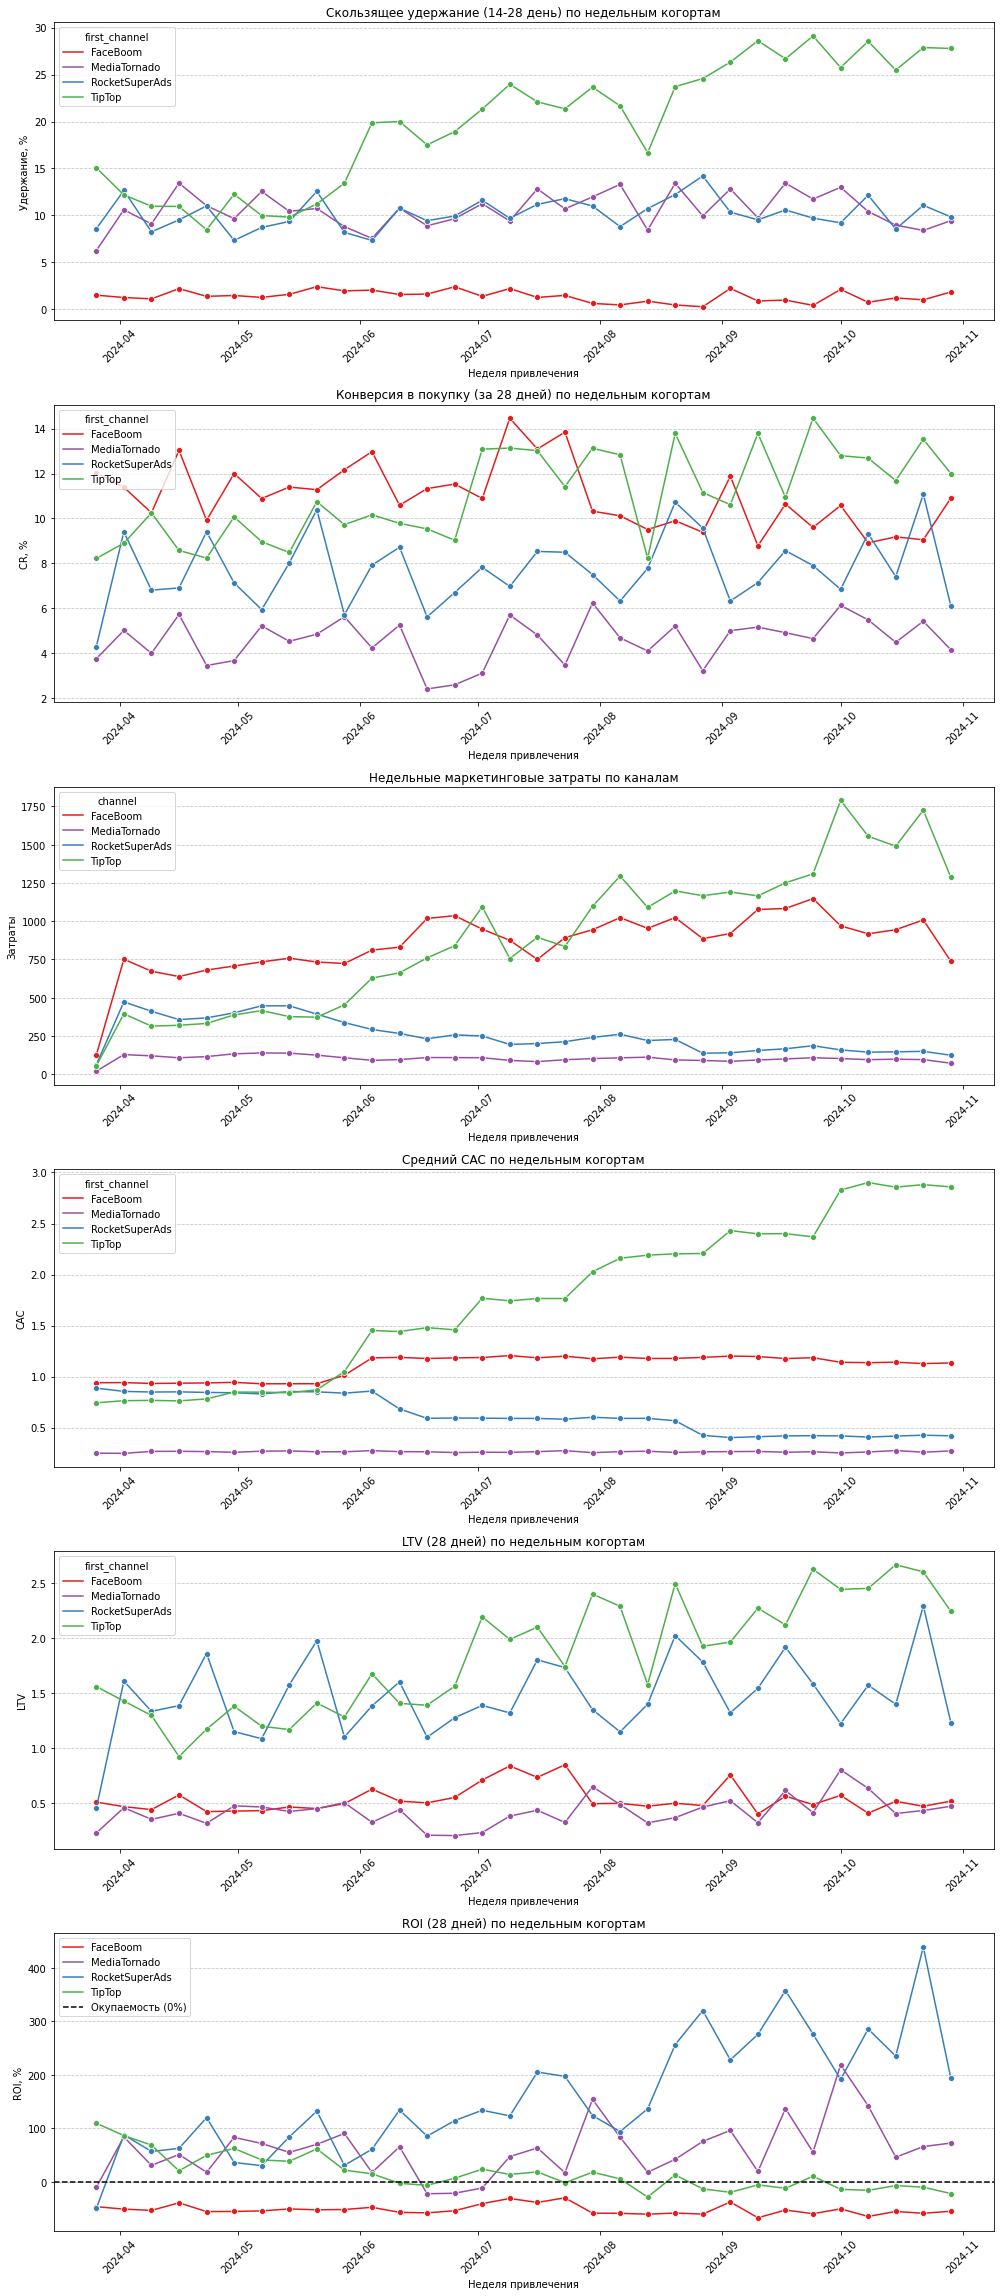

In [31]:
fig, axes = plt.subplots(6, 1, figsize=(14, 32), sharex=False)

#Скользящее удержание
sns.lineplot(data=weekly_metrics, x='acq_week', y='rr_14_28d', hue='first_channel', palette=channel_colors, ax=axes[0], marker='o')
axes[0].set_title('Скользящее удержание (14-28 день) по недельным когортам')
axes[0].set_ylabel('Удержание, %')

#Конверсия
sns.lineplot(data=weekly_metrics, x='acq_week', y='cr_28d', hue='first_channel', palette=channel_colors, ax=axes[1], marker='o')
axes[1].set_title('Конверсия в покупку (за 28 дней) по недельным когортам')
axes[1].set_ylabel('CR, %')

#Затраты
sns.lineplot(data=weekly_costs, x='week', y='costs', hue='channel', palette=channel_colors, ax=axes[2], marker='o')
axes[2].set_title('Недельные маркетинговые затраты по каналам')
axes[2].set_ylabel('Затраты')

#Средний CAC
sns.lineplot(data=weekly_metrics, x='acq_week', y='avg_cac', hue='first_channel', palette=channel_colors, ax=axes[3], marker='o')
axes[3].set_title('Средний CAC по недельным когортам')
axes[3].set_ylabel('CAC')

#LTV
sns.lineplot(data=weekly_metrics, x='acq_week', y='ltv', hue='first_channel', palette=channel_colors, ax=axes[4], marker='o')
axes[4].set_title('LTV (28 дней) по недельным когортам')
axes[4].set_ylabel('LTV')

#ROI
sns.lineplot(data=weekly_metrics, x='acq_week', y='roi', hue='first_channel', palette=channel_colors, ax=axes[5], marker='o')
axes[5].axhline(0, ls='--', color='black', label='Окупаемость (0%)')
axes[5].set_title('ROI (28 дней) по недельным когортам')
axes[5].set_ylabel('ROI, %')
axes[5].legend()

for ax in axes:
    ax.set_xlabel('Неделя привлечения')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Вывод:**

Разбор по каналам показал чёткое разделение на прибыльные и убыточные.

- FaceBoom - самый массовый, но абсолютно не окупается. Удержание почти нулевое, конверсия средняя, а LTV стабильно ниже CAC. ROI всё время в минусе.

- TipTop - качественная аудитория, удержание и конверсия выше среднего, но после запуска спортивного контента их CAC резко взлетел в 2, а потом и в 3 раза, а LTV не компенсировал рост. В итоге ROI с лета ушёл в минус.

- RocketSuperAds и MediaTornado - небольшие по объёму, но стабильно окупаемые. У них низкий CAC, хорошее удержание и высокий LTV. ROI держится в плюсе, часто значительно.

Таким образом, два основных канала FaceBoom и TipTop не вышли на окупаемость за 28 дней. FaceBoom - из-за плохой монетизации аудитории, TipTop - из-за перегрева стоимости привлечения. Прибыль дают только два малых канала. Маркетинговый бюджет явно нужно пересматривать.

## Анализ периода окупаемости маркетинговых вложений

Для источников, которые к 28-му дню не выходят на уровень окупаемости, рассчитаем и визуализируем в виде тепловой карты значения ROI за больший период, например за 8–10 недель.

Разделим данные на недельные когорты по дате привлечения, в качестве интервала наблюдений возьмём недели.

<div style="background-color:#D4D5FF; padding:12px; border-radius:8px; border:1px solid #ffeeba;">
  <b>Для источников, не окупившихся за 28 дней, построим тепловую карту ROI за расширенный период (до 10 недель), чтобы выяснить, окупаются ли они в долгосрочной перспективе.

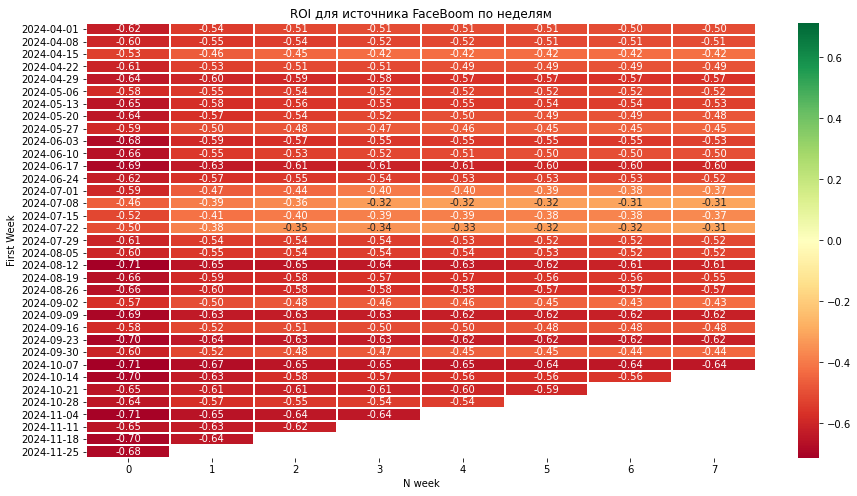

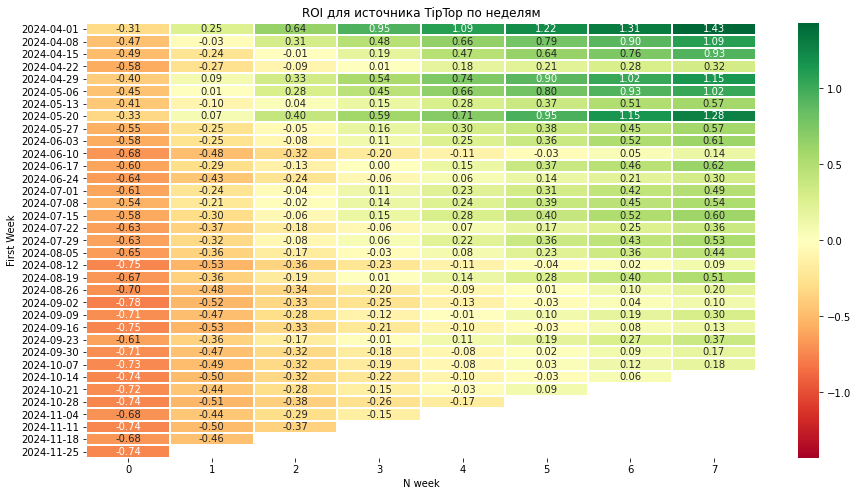

In [32]:
def plot_channel_roi_heatmap(channel):
    #отбираем данные только по нужному каналу
    ch_profiles = profiles[profiles['first_channel'] == channel].copy()
    ch_costs = costs[costs['channel'] == channel].copy()
    ch_orders = orders[orders['user_id'].isin(ch_profiles['user_id'])].copy()
    
    #переводим даты в формат календарных недель
    ch_profiles['first_week'] = ch_profiles['first_dt'].dt.to_period('W').dt.start_time
    ch_costs['week'] = ch_costs['dt'].dt.to_period('W').dt.start_time
    
    #определяем первую неделю пользователя и неделю каждого заказа
    ch_orders['first_week'] = ch_orders['first_dt'].dt.to_period('W').dt.start_time
    ch_orders['order_week'] = ch_orders['event_dt'].dt.to_period('W').dt.start_time
    
    #считаем номер недели лайфтайма пользователя относительно первой недели
    ch_orders['N_week'] = ((ch_orders['order_week'] - ch_orders['first_week']).dt.days // 7)
    
    #считаем сумму затрат по неделям и размер когорт по неделям привлечения
    weekly_costs = ch_costs.groupby('week')['costs'].sum()
    cohort_sizes = ch_profiles.groupby('first_week')['user_id'].nunique()
    
    cohorts = pd.DataFrame({'users': cohort_sizes, 'costs': weekly_costs}).fillna(0)
    
    #убираем когорты без пользователей
    cohorts = cohorts[cohorts['users'] > 0]
    
    #считаем CAC для каждой когорты
    cohorts['cac'] = cohorts['costs'] / cohorts['users']
    
    cohort_revenue = ch_orders.groupby(['first_week', 'N_week'])['revenue'].sum().reset_index()
    revenue_pivot = cohort_revenue.pivot_table(index='first_week', columns='N_week', values='revenue')
    revenue_pivot = revenue_pivot.reindex(cohorts.index).fillna(0)
    
    for w in range(8):
        if w not in revenue_pivot.columns:
            revenue_pivot[w] = 0
            
    revenue_pivot = revenue_pivot.sort_index(axis=1)
    
    max_log_week = visits['session_start'].max().to_period('W').start_time
    invisible_areas = pd.DataFrame(index=revenue_pivot.index, columns=revenue_pivot.columns)
    for cohort_idx in revenue_pivot.index:
        max_possible_week = (max_log_week - cohort_idx).days // 7
        invisible_areas.loc[cohort_idx] = revenue_pivot.columns > max_possible_week
        
    invisible_areas = invisible_areas.astype(bool)
    cum_revenue = revenue_pivot.cumsum(axis=1)
    
    ltv = cum_revenue.div(cohorts['users'], axis=0)
    roi = ltv.div(cohorts['cac'], axis=0) - 1 
    
    cols_to_keep = [c for c in roi.columns if c <= 7]
    roi = roi[cols_to_keep]
    invisible_areas = invisible_areas[cols_to_keep]
    
    roi.index = roi.index.strftime('%Y-%m-%d')
    invisible_areas.index = invisible_areas.index.strftime('%Y-%m-%d')
    
    #сделаем всё что меньше 0 ближе к красному, выше - ближе к зелёному, чтобы не обманываться
    vmin = roi.min().min()
    vmax = roi.max().max()
    max_abs = max(abs(vmin), abs(vmax))
    
    plt.figure(figsize=(15, 8))
    sns.heatmap(
        roi, 
        annot=True, 
        fmt='.2f', 
        cmap='RdYlGn',
        center=0,
        vmin=-max_abs,
        vmax=max_abs,
        linewidths=1,
        linecolor='white',
        mask=invisible_areas 
    )
    plt.title(f'ROI для источника {channel} по неделям')
    plt.ylabel('First Week')
    plt.xlabel('N week')
    plt.show()
plot_channel_roi_heatmap('FaceBoom')
plot_channel_roi_heatmap('TipTop')

**Вывод:**

На тепловых картах ROI за 8 недель видно:

*FaceBoom:*
- Уже к 3–4 неделе ROI стабилизируется на уровне −0.5.
- Дальнейший рост отсутствует - значения остаются в той же отрицательной зоне.
- Вложения в FaceBoom не окупаются даже за 8 недель. Канал абсолютно убыточный.


*TipTop:*
- уже начиная с 4 недели ROI показывает что канал почти безубыточен
- старые когорты показывают результат явно лучше новых, что связано с увеличением стоимости привлечения, поэтому ROI ниже

### Общие выводы

Запуск спортивного контента в июне дал заметный прирост DAU и MAU - аудитория действительно выросла. Однако выручка за те же месяцы не показала сопоставимого роста. 

Главная причина не в трафике, а в экономике привлечения. Стоимость новых пользователей пошла вверх, а их отдача за первые 28 дней не компенсирует затраты. Удержание в целом остаётся слабым, и даже рост вовлечённости не спасает - он идёт за счёт небольшого ядра качественных пользователей, а массовый поток даёт низкую монетизацию.

### Эффективность каналов привлечения

Каналы сильно различаются по окупаемости. Ключевой фактор - не конверсия сама по себе, а баланс между CAC и LTV.

RocketSuperAds - самый стабильный канал. Умеренный CAC, хорошее удержание и LTV. Он уверенно окупается за 28 дней и остаётся в плюсе на всём периоде. Это единственный канал, который можно масштабировать без риска.

MediaTornado - дешёвый, но менее активный канал. Низкий CAC даёт ему запас прочности, и даже при невысокой конверсии он выходит в плюс. Его можно сохранить как стабилизирующий источник.

FaceBoom - крупнейший по объёму, но полностью убыточный. Удержание практически нулевое, конверсия средняя, а LTV стабильно ниже CAC. Даже за 8 недель он не окупается. Это чистый минус.

TipTop - неоднозначный канал. До лета он давал хорошую окупаемость к 5–7 неделе. Но после запуска спортивного контента его CAC вырос в 2 - 3 раза, а LTV не подтянулся. Возможно, стоить пересмотреть стратегию по нему.

### Почему часть каналов не окупается

Основные причины две. Первая - рост стоимости привлечения. После запуска нового контента маркетологи, видимо, переключились на более дорогие аудитории, что особенно ударило по TipTop. Вторая - слабое удержание. Пользователи делают первую покупку, но быстро перестают возвращаться, поэтому даже высокий LTV в начале не успевает окупить CAC за 28 дней.

Проблема не в недостатке трафика, а в его качестве и в том, что привлечение стало слишком дорогим относительно реальной ценности пользователя.

### Рекомендации отделу маркетинга

Первое - пересмотреть распределение бюджета. Увеличить долю RocketSuperAds, сохранить MediaTornado как дешёвый источник. Резко сократить расходы на FaceBoom - он только съедает деньги. По TipTop - либо снизить CAC за счёт более точного таргетинга, либо временно заморозить вложения, пока не разберутся, почему цена так выросла.

Второе - сместить фокус с валового привлечения на экономику. Оценивать каналы не по количеству новых пользователей, а по CAC, LTV и удержанию на 14–28 дни. Это поможет быстрее отсекать убыточные источники.

Третье - подумать над повышением удержания внутри продукта. Спортивный контент привлекает внимание, но не закрепляет пользователей. Нужны механики, которые заставят возвращаться чаще, - тогда и LTV подтянется, и окупаемость улучшится.

### Итог
В целом анализ показывает проблемы в качество трафика. Из четырёх каналов только один стабильно прибыльный, ещё один - условно приемлемый, а два основных, на которые уходит львиная доля маркетингового бюджета - системно убыточны. Дальнейший рост возможен только при жёстком контроле маркетингового бюджета, смещении акцента на удержание и пересмотре стратегии по TipTop. Без этих мер рост аудитории так и останется без выручки.